In [ ]:
import os
import time
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import librosa
import joblib
from tensorflow.keras import layers, models
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from IPython import display

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

print('TensorFlow', tf.__version__)
print(tf.config.list_physical_devices('GPU'))
!nvidia-smi -L

TensorFlow 2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-2d03b524-016a-f1a6-f1fe-9a9e707afbb5)


In [ ]:
DATASET_PATH = 'data/mini_speech_commands'
data_dir = pathlib.Path(DATASET_PATH)
if not data_dir.exists():
    tf.keras.utils.get_file(
        'mini_speech_commands.zip',
        origin='http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip',
        extract=True, cache_dir='.', cache_subdir='data')
if not data_dir.exists():
    data_dir = list(pathlib.Path('data').glob('*/mini_speech_commands'))[0]

train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=data_dir,
    batch_size=64,
    validation_split=0.2,
    seed=0,
    output_sequence_length=16000,
    subset='both')

label_names = np.array(train_ds.class_names)
print('Klasės:', label_names)

182082353/182082353 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 8000 files belonging to 8 classes.
Using 6400 files for training.
Using 1600 files for validation.
Klasės: ['down' 'go' 'left' 'no' 'right' 'stop' 'up' 'yes']


In [ ]:
def to_numpy(ds):
    x, y = [], []
    for audio, labels in ds:
        x.append(audio.numpy()[:, :, 0])
        y.append(labels.numpy())
    return np.concatenate(x), np.concatenate(y)

x_train, y_train = to_numpy(train_ds)
x_rest, y_rest = to_numpy(val_ds)
half = len(x_rest) // 2
x_val, y_val = x_rest[:half], y_rest[:half]
x_test, y_test = x_rest[half:], y_rest[half:]

print('train:', x_train.shape, 'val:', x_val.shape, 'test:', x_test.shape)

train: (6400, 16000) val: (800, 16000) test: (800, 16000)


       train  val  test
down     801   92   107
go       814   98    88
left     791  104   105
no       791  115    94
right    814  102    84
stop     784   99   117
up       799   91   110
yes      806   99    95


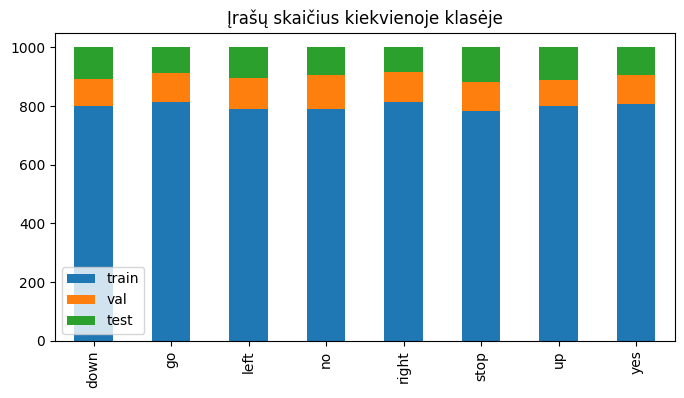

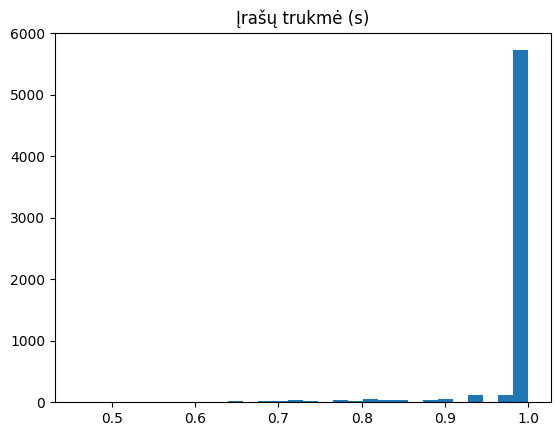

In [ ]:
counts = pd.DataFrame({
    'train': np.bincount(y_train, minlength=8),
    'val': np.bincount(y_val, minlength=8),
    'test': np.bincount(y_test, minlength=8)}, index=label_names)
print(counts)
counts.plot.bar(stacked=True, figsize=(8, 4), title='Įrašų skaičius kiekvienoje klasėje')
plt.show()

lengths = np.array([np.max(np.nonzero(x)[0]) + 1 if np.any(x) else 0 for x in x_train])
plt.hist(lengths / 16000, bins=30)
plt.title('Įrašų trukmė (s)')
plt.show()

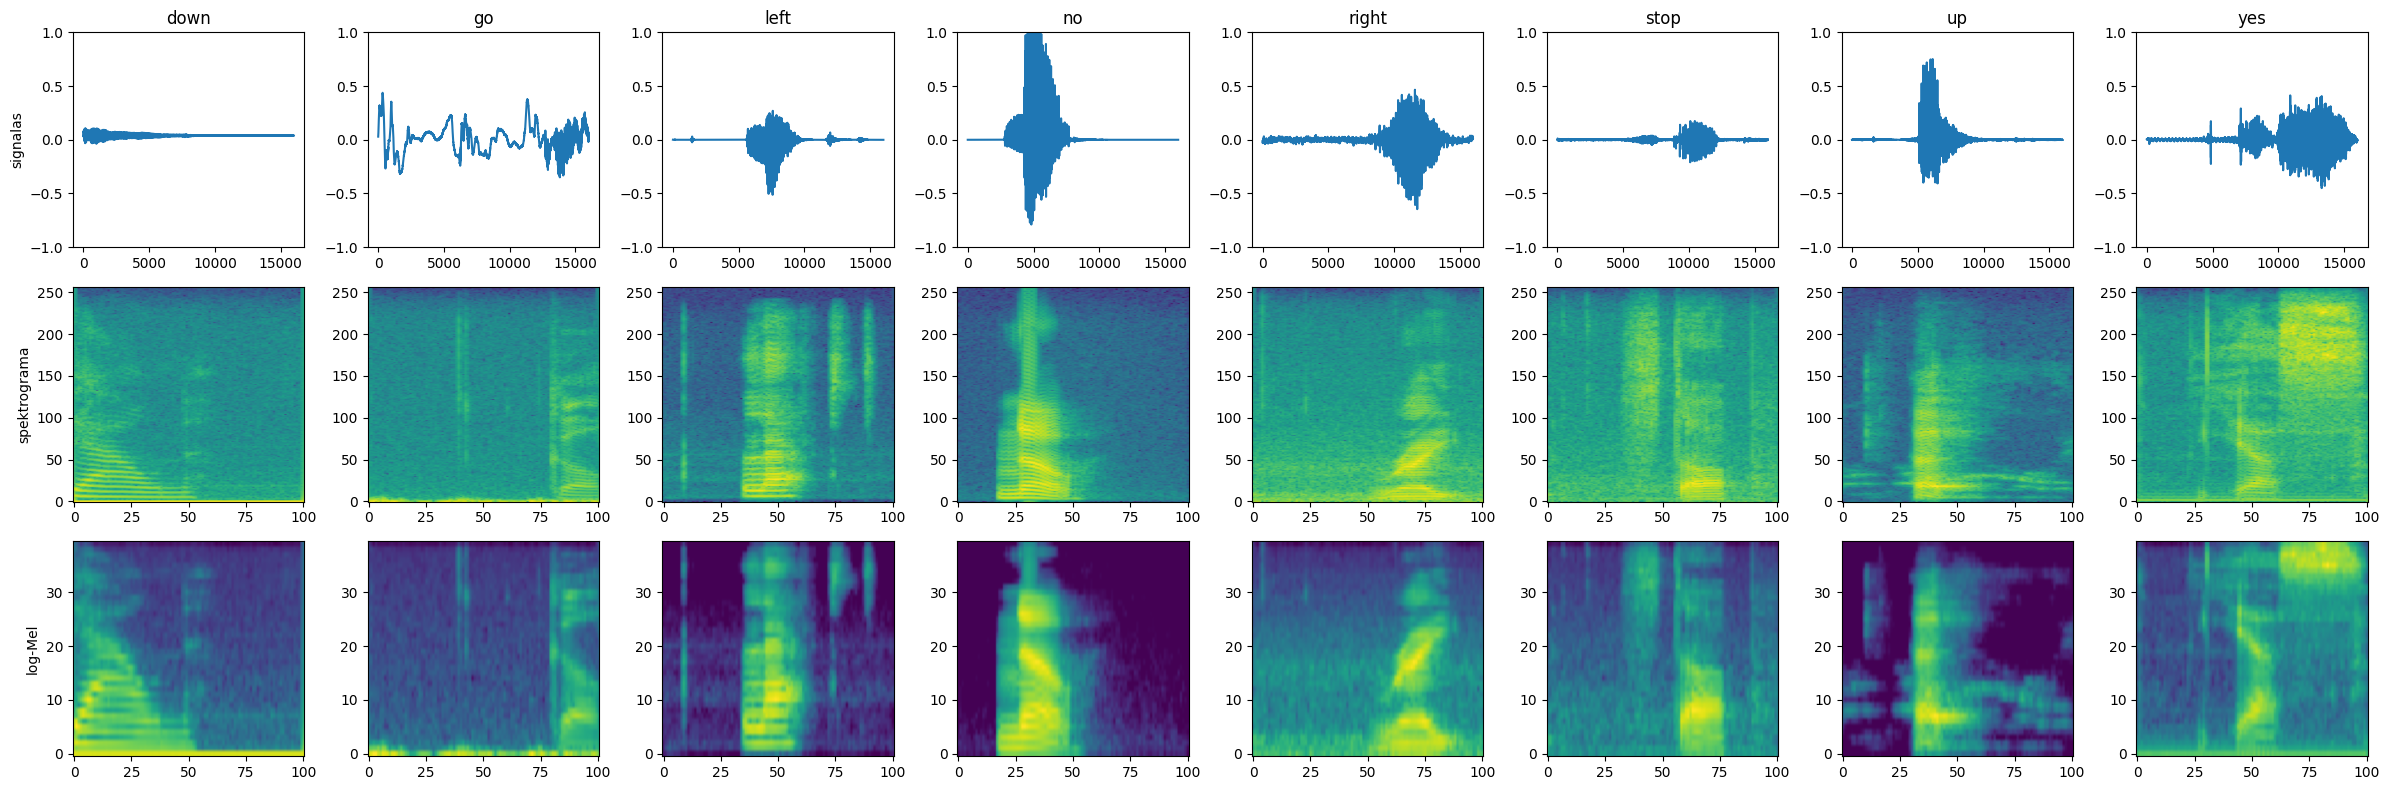

down


go


left


no


right


stop


up


yes


In [ ]:
fig, axes = plt.subplots(3, 8, figsize=(24, 8))
for i, name in enumerate(label_names):
    x = x_train[np.where(y_train == i)[0][0]]
    axes[0, i].plot(x)
    axes[0, i].set_ylim(-1, 1)
    axes[0, i].set_title(name)
    spec = np.abs(librosa.stft(x, n_fft=512, hop_length=160))
    axes[1, i].imshow(np.log(spec + 1e-6), origin='lower', aspect='auto')
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=x, sr=16000, n_fft=512, hop_length=160, n_mels=40))
    axes[2, i].imshow(mel, origin='lower', aspect='auto')
axes[0, 0].set_ylabel('signalas')
axes[1, 0].set_ylabel('spektrograma')
axes[2, 0].set_ylabel('log-Mel')
plt.tight_layout()
plt.show()

for i, name in enumerate(label_names):
    print(name)
    display.display(display.Audio(x_train[np.where(y_train == i)[0][0]], rate=16000))

In [ ]:
def get_spectrogram(waveform):
    spectrogram = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    spectrogram = tf.abs(spectrogram)
    return spectrogram[..., tf.newaxis].numpy()

def get_log_mel(waveform):
    mel = librosa.feature.melspectrogram(y=waveform, sr=16000, n_fft=512, hop_length=160, n_mels=40)
    return librosa.power_to_db(mel).T

def get_mfcc(waveform):
    return librosa.feature.mfcc(y=waveform, sr=16000, n_mfcc=13, n_fft=512, hop_length=160, n_mels=40).T

def make_features(x, func):
    return np.array([func(w) for w in x])

In [ ]:
start = time.time()
spec_train, spec_val, spec_test = [make_features(x, get_spectrogram) for x in (x_train, x_val, x_test)]
mel_train, mel_val, mel_test = [make_features(x, get_log_mel)[..., np.newaxis] for x in (x_train, x_val, x_test)]
mfcc_train, mfcc_val, mfcc_test = [make_features(x, get_mfcc) for x in (x_train, x_val, x_test)]
print('spektrograma', spec_train.shape, '| log-Mel', mel_train.shape, '| MFCC', mfcc_train.shape)
print(f'požymių išskyrimo laikas: {time.time() - start:.0f} s')

spektrograma (6400, 124, 129, 1) | log-Mel (6400, 101, 40, 1) | MFCC (6400, 101, 13)
požymių išskyrimo laikas: 120 s


In [ ]:
results = []
conf_matrices = {}
train_info = []

def specificity(cm):
    spec = []
    for i in range(len(cm)):
        fp = cm[:, i].sum() - cm[i, i]
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        spec.append(tn / (tn + fp))
    return np.mean(spec)

def evaluate(name, predict, data):
    conf_matrices[name] = {}
    for split, (x, y) in data.items():
        y_pred = predict(x)
        cm = confusion_matrix(y, y_pred)
        conf_matrices[name][split] = cm
        results.append({
            'modelis': name, 'imtis': split,
            'tikslumas': accuracy_score(y, y_pred),
            'preciziškumas': precision_score(y, y_pred, average='macro', zero_division=0),
            'jautrumas': recall_score(y, y_pred, average='macro', zero_division=0),
            'specifiškumas': specificity(cm)})
    print(pd.DataFrame(results[-3:]).round(4))

def plot_history(history, name):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history['loss'], label='train')
    ax[0].plot(history.history['val_loss'], label='val')
    ax[0].set_title(name + ' - loss')
    ax[0].set_xlabel('epocha')
    ax[0].legend()
    ax[1].plot(history.history['accuracy'], label='train')
    ax[1].plot(history.history['val_accuracy'], label='val')
    ax[1].set_title(name + ' - accuracy')
    ax[1].set_xlabel('epocha')
    ax[1].legend()
    plt.show()

def train_keras(model, name, x_tr, x_v, epochs=30):
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    early_stop = tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
    start = time.time()
    history = model.fit(x_tr, y_train, validation_data=(x_v, y_val),
                        epochs=epochs, batch_size=64, callbacks=[early_stop])
    train_time = time.time() - start
    train_info.append({'modelis': name, 'parametrai': model.count_params(),
                       'epochos': len(history.history['loss']), 'laikas (s)': round(train_time, 1)})
    plot_history(history, name)
    model.save(f'{name}.keras')
    return history

def keras_predict(model):
    return lambda x: np.argmax(model.predict(x, verbose=0), axis=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,611 (6.20 MB)

 Trainable params: 1,625,608 (6.20 MB)

 Non-trainable params: 3 (16.00 B)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.3659 - loss: 1.7572 - val_accuracy: 0.5863 - val_loss: 1.3489
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5850 - loss: 1.2043 - val_accuracy: 0.6988 - val_loss: 0.9671
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6808 - loss: 0.9016 - val_accuracy: 0.7475 - val_loss: 0.8011
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7361 - loss: 0.7392 - val_accuracy: 0.7887 - val_loss: 0.6601
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7764 - loss: 0.6295 - val_accuracy: 0.8050 - val_loss: 0.5971
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8119 - loss: 0.5389 - val_accuracy: 0.8175 - val_loss: 0.5800
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8220 - loss: 0.4984 - val_accuracy: 0.8313 - val_loss: 0.5312
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8487 - loss: 0.4405 - val_accurac

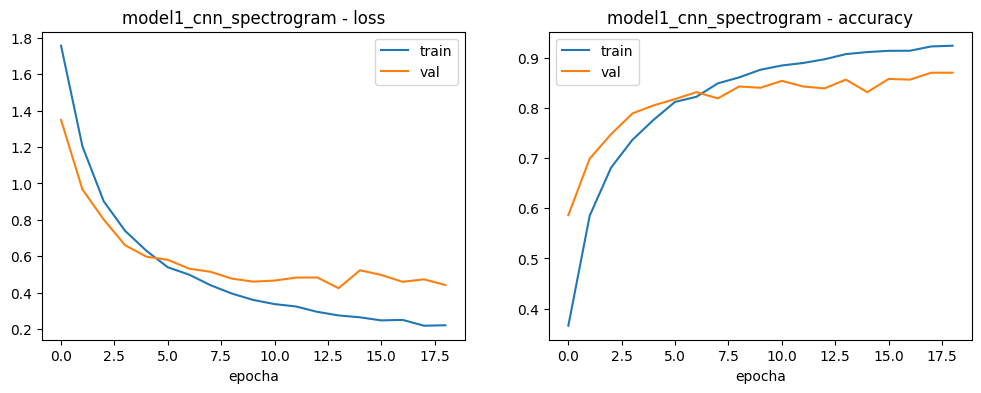

                  modelis  imtis  tikslumas  preciziškumas  jautrumas  \
0  model1_cnn_spectrogram  train     0.9636         0.9643     0.9637   
1  model1_cnn_spectrogram    val     0.8562         0.8599     0.8590   
2  model1_cnn_spectrogram   test     0.8588         0.8601     0.8582   

   specifiškumas  
0         0.9948  
1         0.9795  
2         0.9799  


In [ ]:
norm1 = layers.Normalization()
norm1.adapt(spec_train)

model1 = models.Sequential([
    layers.Input(shape=spec_train.shape[1:]),
    layers.Resizing(32, 32),
    norm1,
    layers.Conv2D(32, 3, activation='relu'),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(8, activation='softmax'),
])
model1.summary()
train_keras(model1, 'model1_cnn_spectrogram', spec_train, spec_val)
evaluate('model1_cnn_spectrogram', keras_predict(model1),
         {'train': (spec_train, y_train), 'val': (spec_val, y_val), 'test': (spec_test, y_test)})

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 101, 40, 1)     │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 99, 38, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 49, 19, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 47, 17, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 8, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 23, 8, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 11776)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,507,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,527,307 (5.83 MB)

 Trainable params: 1,527,304 (5.83 MB)

 Non-trainable params: 3 (16.00 B)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.3562 - loss: 1.6834 - val_accuracy: 0.6675 - val_loss: 1.1050
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5920 - loss: 1.1191 - val_accuracy: 0.7300 - val_loss: 0.8175
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6839 - loss: 0.8613 - val_accuracy: 0.7788 - val_loss: 0.6390
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7430 - loss: 0.7033 - val_accuracy: 0.8125 - val_loss: 0.5410
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7864 - loss: 0.5935 - val_accuracy: 0.8413 - val_loss: 0.4758
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8156 - loss: 0.5268 - val_accuracy: 0.8413 - val_loss: 0.4406
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8352 - loss: 0.4558 - val_accuracy: 0.8512 - val_loss: 0.4317
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8570 - loss: 0.4034 - val_accuracy

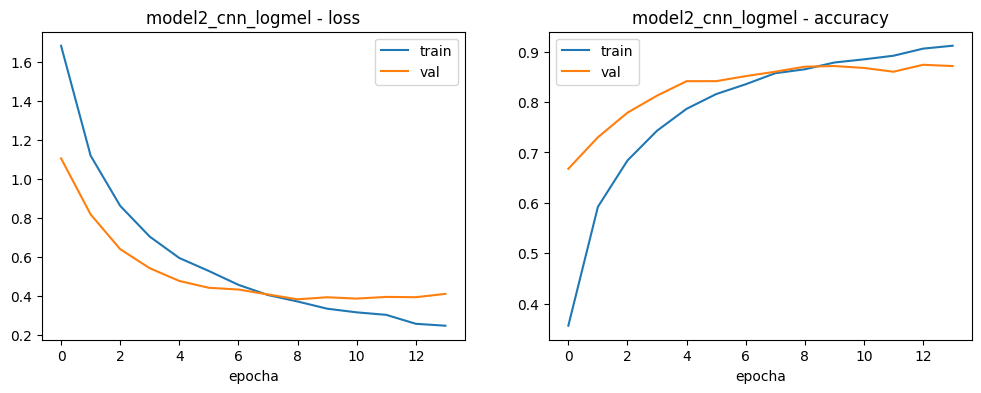

             modelis  imtis  tikslumas  preciziškumas  jautrumas  \
0  model2_cnn_logmel  train     0.9584         0.9591     0.9585   
1  model2_cnn_logmel    val     0.8700         0.8737     0.8709   
2  model2_cnn_logmel   test     0.8700         0.8741     0.8690   

   specifiškumas  
0         0.9941  
1         0.9814  
2         0.9814  


In [ ]:
norm2 = layers.Normalization()
norm2.adapt(mel_train)

model2 = models.Sequential([
    layers.Input(shape=mel_train.shape[1:]),
    norm2,
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(8, activation='softmax'),
])
model2.summary()
train_keras(model2, 'model2_cnn_logmel', mel_train, mel_val)
evaluate('model2_cnn_logmel', keras_predict(model2),
         {'train': (mel_train, y_train), 'val': (mel_val, y_val), 'test': (mel_test, y_test)})

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 3985, 16)       │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 996, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 994, 32)        │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 248, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 246, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 61, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,496 (52.72 KB)

 Trainable params: 13,496 (52.72 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.1575 - loss: 2.0645 - val_accuracy: 0.1700 - val_loss: 2.0075
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.2269 - loss: 1.9563 - val_accuracy: 0.2688 - val_loss: 1.8844
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.2912 - loss: 1.8555 - val_accuracy: 0.3025 - val_loss: 1.8021
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.3262 - loss: 1.7819 - val_accuracy: 0.3038 - val_loss: 1.7390
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.3523 - loss: 1.7108 - val_accuracy: 0.3462 - val_loss: 1.6833
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3738 - loss: 1.6784 - val_accuracy: 0.3663 - val_loss: 1.6457
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3889 - loss: 1.6366 - val_accuracy: 0.3925 - val_loss: 1.5980
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4087 - loss: 1.5954 - val_accu

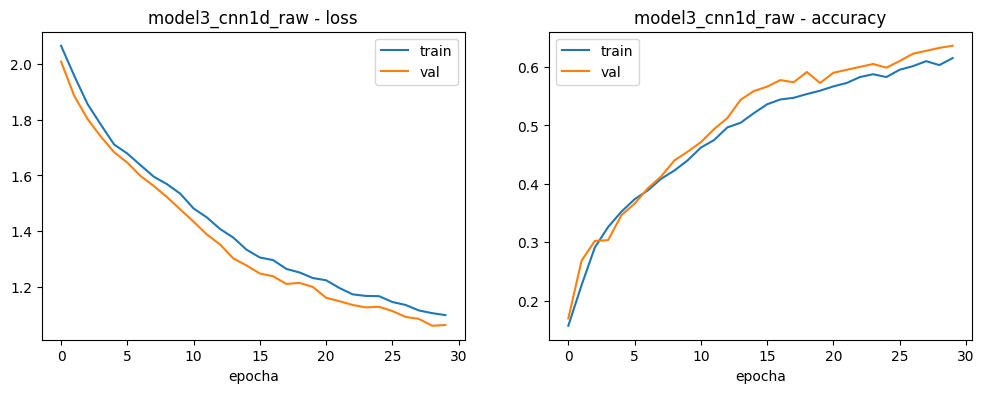

            modelis  imtis  tikslumas  preciziškumas  jautrumas  specifiškumas
0  model3_cnn1d_raw  train     0.6502         0.6514     0.6501         0.9500
1  model3_cnn1d_raw    val     0.6325         0.6382     0.6383         0.9474
2  model3_cnn1d_raw   test     0.6675         0.6702     0.6631         0.9526


In [ ]:
raw_train, raw_val, raw_test = x_train[..., np.newaxis], x_val[..., np.newaxis], x_test[..., np.newaxis]

model3 = models.Sequential([
    layers.Input(shape=(16000, 1)),
    layers.Conv1D(16, 64, strides=4, activation='relu'),
    layers.MaxPooling1D(4),
    layers.Conv1D(32, 3, activation='relu'),
    layers.MaxPooling1D(4),
    layers.Conv1D(64, 3, activation='relu'),
    layers.MaxPooling1D(4),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(8, activation='softmax'),
])
model3.summary()
train_keras(model3, 'model3_cnn1d_raw', raw_train, raw_val)
evaluate('model3_cnn1d_raw', keras_predict(model3),
         {'train': (raw_train, y_train), 'val': (raw_val, y_val), 'test': (raw_test, y_test)})

In [ ]:
rf_train = mfcc_train.reshape(len(mfcc_train), -1)
rf_val = mfcc_val.reshape(len(mfcc_val), -1)
rf_test = mfcc_test.reshape(len(mfcc_test), -1)

rf_mean = RandomForestClassifier(n_estimators=250, random_state=seed, n_jobs=-1)
rf_mean.fit(mfcc_train.mean(axis=1), y_train)
print('Miškas su MFCC vidurkiais, test tikslumas:', rf_mean.score(mfcc_test.mean(axis=1), y_test))

model4 = RandomForestClassifier(n_estimators=250, random_state=seed, n_jobs=-1)
start = time.time()
model4.fit(rf_train, y_train)
train_info.append({'modelis': 'model4_rf_mfcc', 'parametrai': '-', 'epochos': '-',
                   'laikas (s)': round(time.time() - start, 1)})
joblib.dump(model4, 'model4_rf_mfcc.joblib')
evaluate('model4_rf_mfcc', model4.predict,
         {'train': (rf_train, y_train), 'val': (rf_val, y_val), 'test': (rf_test, y_test)})

Miškas su MFCC vidurkiais, test tikslumas: 0.44875
          modelis  imtis  tikslumas  preciziškumas  jautrumas  specifiškumas
0  model4_rf_mfcc  train     1.0000         1.0000     1.0000         1.0000
1  model4_rf_mfcc    val     0.7238         0.7283     0.7281         0.9606
2  model4_rf_mfcc   test     0.7525         0.7594     0.7500         0.9646


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 101, 13)        │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 101, 64)        │        15,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,675 (158.89 KB)

 Trainable params: 40,648 (158.78 KB)

 Non-trainable params: 27 (112.00 B)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.1827 - loss: 2.0387 - val_accuracy: 0.2313 - val_loss: 1.9458
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.2947 - loss: 1.7891 - val_accuracy: 0.3975 - val_loss: 1.5685
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4519 - loss: 1.3823 - val_accuracy: 0.5475 - val_loss: 1.2002
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6203 - loss: 1.0149 - val_accuracy: 0.6888 - val_loss: 0.8913
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7481 - loss: 0.7253 - val_accuracy: 0.7812 - val_loss: 0.6318
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8327 - loss: 0.5125 - val_accuracy: 0.8487 - val_loss: 0.4739
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8734 - loss: 0.3902 - val_accuracy: 0.8413 - val_loss: 0.4331
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9020 - loss: 0.3097 - val_accu

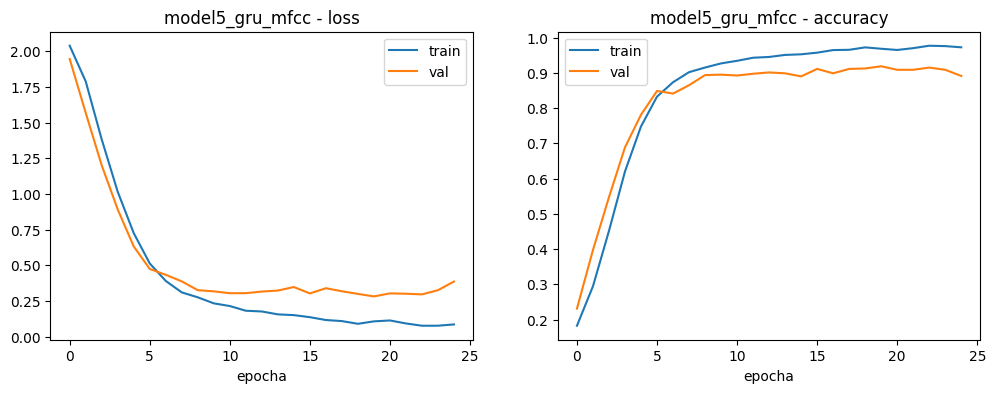

           modelis  imtis  tikslumas  preciziškumas  jautrumas  specifiškumas
0  model5_gru_mfcc  train     0.9753         0.9757     0.9754         0.9965
1  model5_gru_mfcc    val     0.9188         0.9196     0.9196         0.9884
2  model5_gru_mfcc   test     0.9438         0.9445     0.9452         0.9920


In [ ]:
norm5 = layers.Normalization()
norm5.adapt(mfcc_train)

model5 = models.Sequential([
    layers.Input(shape=mfcc_train.shape[1:]),
    norm5,
    layers.GRU(64, return_sequences=True),
    layers.GRU(64),
    layers.Dropout(0.3),
    layers.Dense(8, activation='softmax'),
])
model5.summary()
train_keras(model5, 'model5_gru_mfcc', mfcc_train, mfcc_val)
evaluate('model5_gru_mfcc', keras_predict(model5),
         {'train': (mfcc_train, y_train), 'val': (mfcc_val, y_val), 'test': (mfcc_test, y_test)})

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_3 (Normalization) │ (None, 101, 40, 1)     │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 101, 40, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 101, 40, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 101, 20, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 101, 20, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 101, 20, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 101, 10, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 101, 640)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │       271,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291,339 (1.11 MB)

 Trainable params: 291,144 (1.11 MB)

 Non-trainable params: 195 (784.00 B)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.3803 - loss: 1.7064 - val_accuracy: 0.3175 - val_loss: 1.8353
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.7616 - loss: 0.7396 - val_accuracy: 0.4500 - val_loss: 1.4217
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.8509 - loss: 0.4644 - val_accuracy: 0.7088 - val_loss: 0.8439
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9033 - loss: 0.3224 - val_accuracy: 0.7788 - val_loss: 0.6330
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9287 - loss: 0.2352 - val_accuracy: 0.8913 - val_loss: 0.3526
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9491 - loss: 0.1778 - val_accuracy: 0.9000 - val_loss: 0.2917
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9578 - loss: 0.1392 - val_accuracy: 0.9162 - val_loss: 0.2548
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9677 - loss: 0.1107 - val_accu

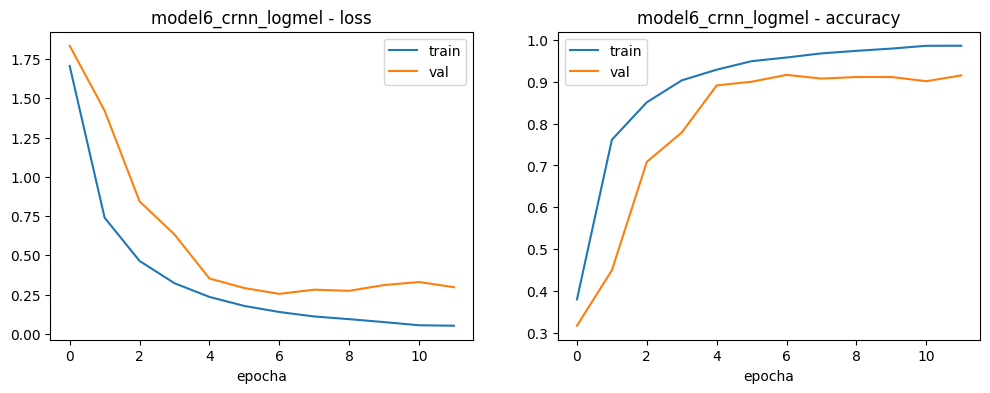

              modelis  imtis  tikslumas  preciziškumas  jautrumas  \
0  model6_crnn_logmel  train     0.9694         0.9703     0.9694   
1  model6_crnn_logmel    val     0.9162         0.9175     0.9169   
2  model6_crnn_logmel   test     0.9288         0.9327     0.9279   

   specifiškumas  
0         0.9956  
1         0.9881  
2         0.9898  


In [ ]:
norm6 = layers.Normalization()
norm6.adapt(mel_train)

model6 = models.Sequential([
    layers.Input(shape=mel_train.shape[1:]),
    norm6,
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((1, 2)),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((1, 2)),
    layers.Reshape((101, 10 * 64)),
    layers.Bidirectional(layers.GRU(64)),
    layers.Dropout(0.3),
    layers.Dense(8, activation='softmax'),
])
model6.summary()
train_keras(model6, 'model6_crnn_logmel', mel_train, mel_val, epochs=25)
evaluate('model6_crnn_logmel', keras_predict(model6),
         {'train': (mel_train, y_train), 'val': (mel_val, y_val), 'test': (mel_test, y_test)})

In [ ]:
results_df = pd.DataFrame(results)
results_table = results_df.pivot(index='modelis', columns='imtis')
results_table = results_table.reindex(columns=['train', 'val', 'test'], level=1)
results_table.round(4).to_csv('rezultatai.csv')
results_table.round(4)

tikslumas                 preciziškumas          \
imtis                      train     val    test         train     val   
modelis                                                                  
model1_cnn_spectrogram    0.9636  0.8562  0.8588        0.9643  0.8599   
model2_cnn_logmel         0.9584  0.8700  0.8700        0.9591  0.8737   
model3_cnn1d_raw          0.6502  0.6325  0.6675        0.6514  0.6382   
model4_rf_mfcc            1.0000  0.7238  0.7525        1.0000  0.7283   
model5_gru_mfcc           0.9753  0.9188  0.9438        0.9757  0.9196   
model6_crnn_logmel        0.9694  0.9162  0.9288        0.9703  0.9175   

                               jautrumas                 specifiškumas  \
imtis                     test     train     val    test         train   
modelis                                                                  
model1_cnn_spectrogram  0.8601    0.9637  0.8590  0.8582        0.9948   
model2_cnn_logmel       0.8741    0.9585  0.8709  0.8690        0.9941   
model3_cnn1d_raw        0.6702    0.6501  0.6383  0.6631        0.9500   
model4_rf_mfcc          0.7594    1.0000  0.7281  0.7500        1.0000   
model5_gru_mfcc         0.9445    0.9754  0.9196  0.9452        0.9965   
model6_crnn_logmel      0.9327    0.9694  0.9169  0.9279        0.9956   

                                        
imtis                      val    test  
modelis                                 
model1_cnn_spectrogram  0.9795  0.9799  
model2_cnn_logmel       0.9814  0.9814  
model3_cnn1d_raw        0.9474  0.9526  
model4_rf_mfcc          0.9606  0.9646  
model5_gru_mfcc         0.9884  0.9920  
model6_crnn_logmel      0.9881  0.9898

In [ ]:
pd.DataFrame(train_info)

,modelis,parametrai,epochos,laikas (s)
0,model1_cnn_spectrogram,1625611,19,27.0
1,model2_cnn_logmel,1527307,14,20.8
2,model3_cnn1d_raw,13496,30,48.0
3,model4_rf_mfcc,-,-,56.1
4,model5_gru_mfcc,40675,25,38.4
5,model6_crnn_logmel,291339,12,52.4


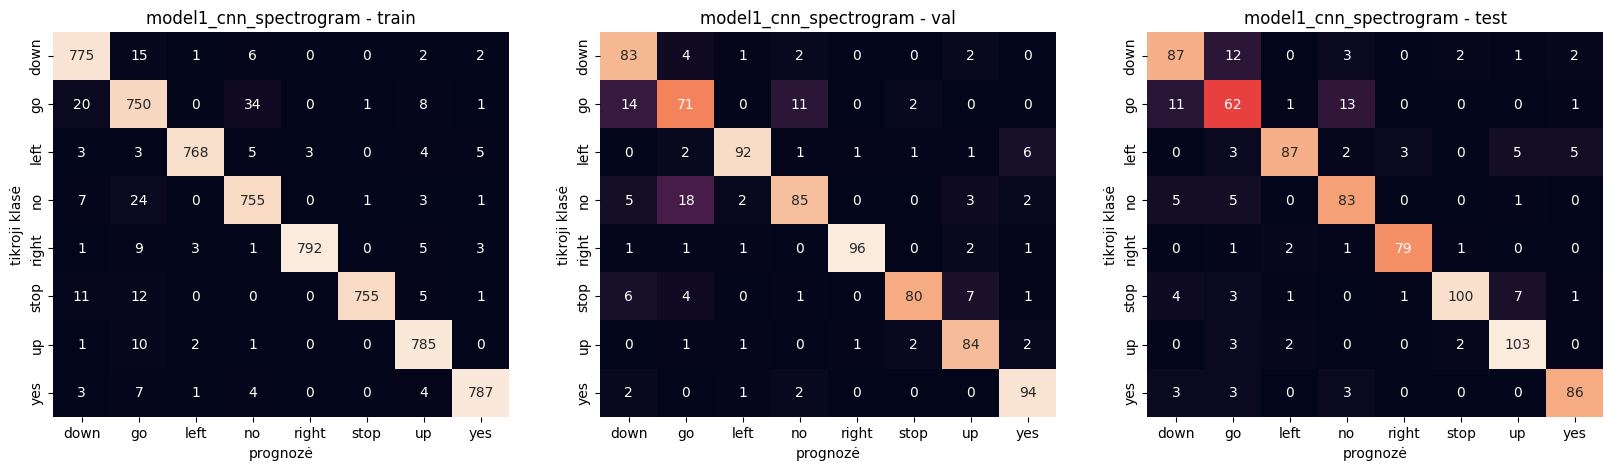

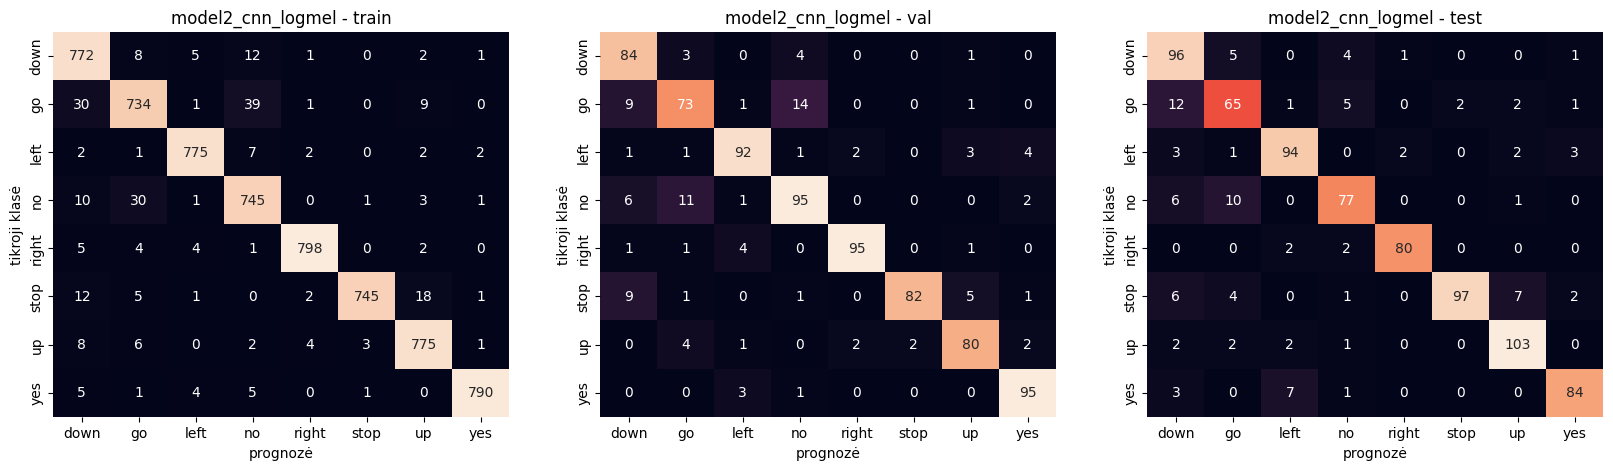

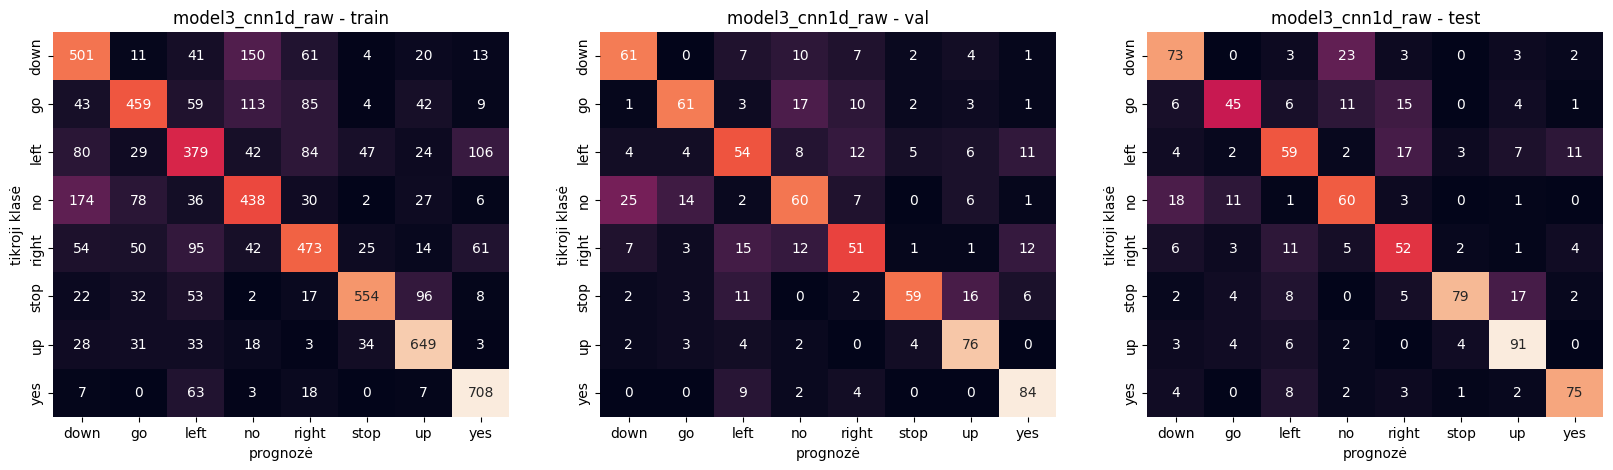

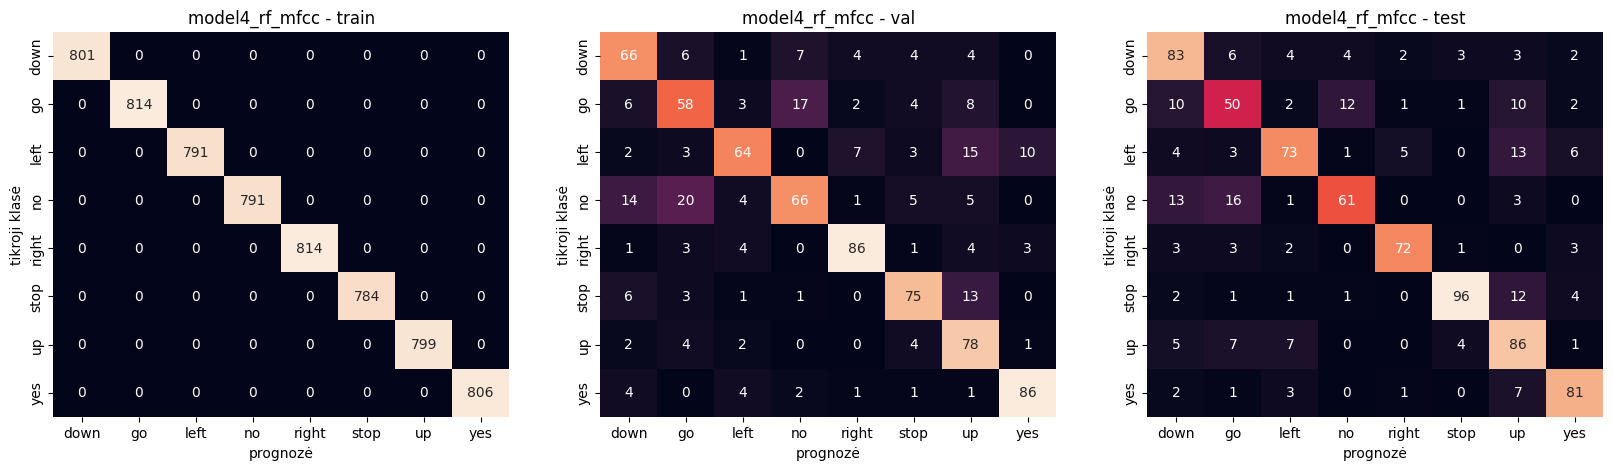

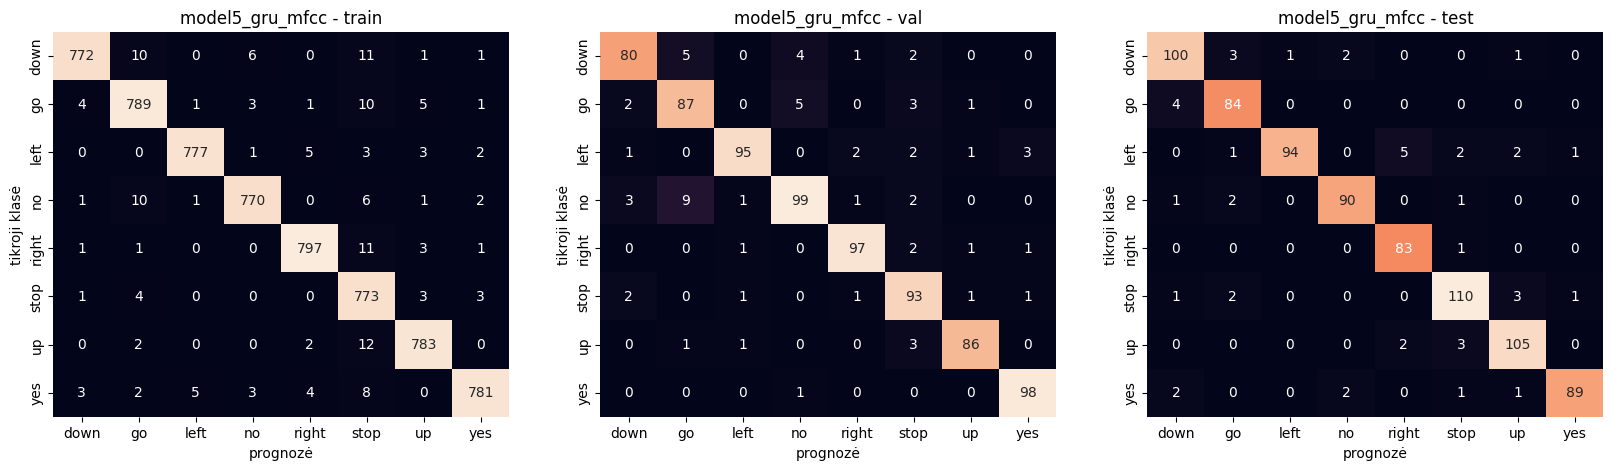

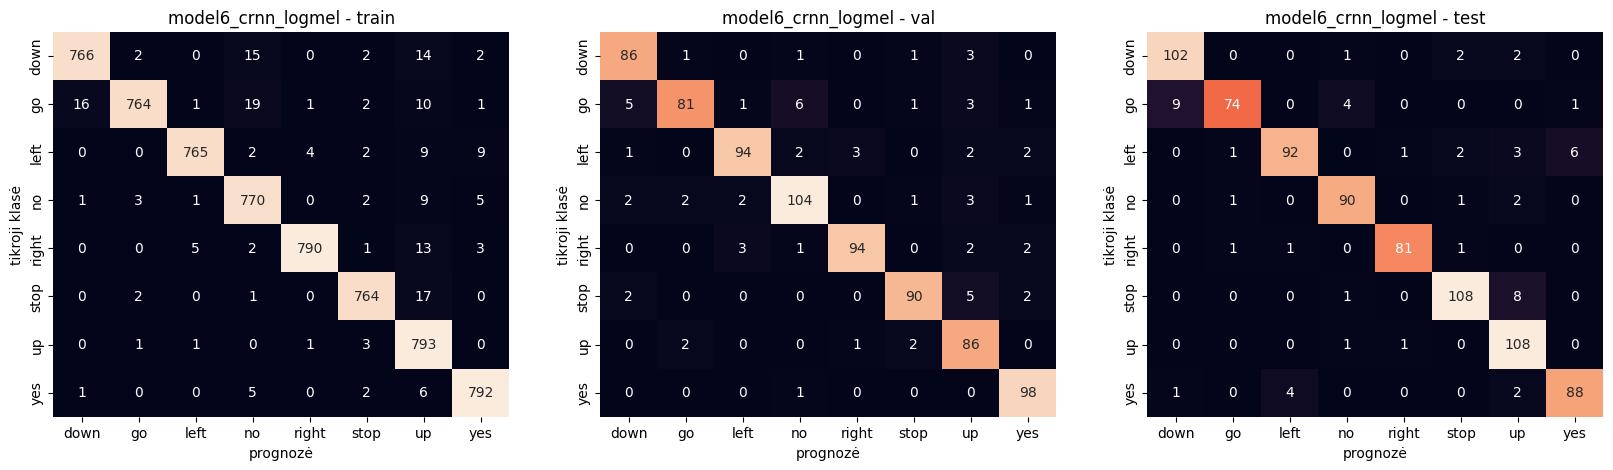

In [ ]:
for name in conf_matrices:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for ax, split in zip(axes, ['train', 'val', 'test']):
        sns.heatmap(conf_matrices[name][split], annot=True, fmt='d', cbar=False, ax=ax,
                    xticklabels=label_names, yticklabels=label_names)
        ax.set_title(f'{name} - {split}')
        ax.set_xlabel('prognozė')
        ax.set_ylabel('tikroji klasė')
    plt.show()

In [ ]:
recall_per_class = {}
for name in conf_matrices:
    cm = conf_matrices[name]['test']
    recall_per_class[name] = np.diag(cm) / cm.sum(axis=1)
recall_df = pd.DataFrame(recall_per_class, index=label_names)
recall_df['vidurkis'] = recall_df.mean(axis=1)
print(recall_df.sort_values('vidurkis', ascending=False).round(3))

total = sum(conf_matrices[name]['test'] for name in conf_matrices)
pairs = []
for i in range(8):
    for j in range(i + 1, 8):
        pairs.append((label_names[i], label_names[j], total[i, j] + total[j, i]))
pairs.sort(key=lambda p: -p[2])
print('\nLabiausiai maišomos poros:')
for a, b, n in pairs[:5]:
    print(a, '-', b, ':', n)

       model1_cnn_spectrogram  model2_cnn_logmel  model3_cnn1d_raw  \
up                      0.936              0.936             0.827   
right                   0.940              0.952             0.619   
yes                     0.905              0.884             0.789   
down                    0.813              0.897             0.682   
stop                    0.855              0.829             0.675   
no                      0.883              0.819             0.638   
left                    0.829              0.895             0.562   
go                      0.705              0.739             0.511   

       model4_rf_mfcc  model5_gru_mfcc  model6_crnn_logmel  vidurkis  
up              0.782            0.955               0.982     0.903  
right           0.857            0.988               0.964     0.887  
yes             0.853            0.937               0.926     0.882  
down            0.776            0.935               0.953     0.843  
stop          

In [ ]:
x_cv = np.concatenate([rf_train, rf_val])
y_cv = np.concatenate([y_train, y_val])
scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1),
                         x_cv, y_cv, cv=5, scoring='accuracy')
print('Tikslumas kiekviename poaibyje:', scores.round(4))
print(f'Vidurkis: {scores.mean():.4f} ± {scores.std():.4f}')

Tikslumas kiekviename poaibyje: [0.7194 0.7118 0.6889 0.7118 0.6944]
Vidurkis: 0.7053 ± 0.0116


In [ ]:
def classify(path, model_name):
    x, _ = librosa.load(path, sr=16000)
    x = np.pad(x[:16000], (0, max(0, 16000 - len(x))))
    if model_name == 'model4_rf_mfcc':
        model = joblib.load('model4_rf_mfcc.joblib')
        probs = model.predict_proba(get_mfcc(x).reshape(1, -1))[0]
    else:
        model = tf.keras.models.load_model(f'{model_name}.keras')
        if model_name == 'model1_cnn_spectrogram':
            features = get_spectrogram(x)
        elif model_name == 'model3_cnn1d_raw':
            features = x[:, np.newaxis]
        elif model_name == 'model5_gru_mfcc':
            features = get_mfcc(x)
        else:
            features = get_log_mel(x)[..., np.newaxis]
        probs = model.predict(features[np.newaxis], verbose=0)[0]
    return label_names[np.argmax(probs)], probs

label_names = np.array(['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes'])
file = str(data_dir / 'no' / sorted(os.listdir(data_dir / 'no'))[0])
display.display(display.Audio(file))
for name in ['model1_cnn_spectrogram', 'model2_cnn_logmel', 'model3_cnn1d_raw',
             'model4_rf_mfcc', 'model5_gru_mfcc', 'model6_crnn_logmel']:
    label, probs = classify(file, name)
    print(f'{name}: {label}  ({probs.max():.2f})')

model1_cnn_spectrogram: no  (0.92)
model2_cnn_logmel: no  (0.80)
model3_cnn1d_raw: no  (0.44)
model4_rf_mfcc: no  (0.76)


model5_gru_mfcc: no  (1.00)


model6_crnn_logmel: no  (0.98)


In [ ]:
!zip -q modeliai.zip *.keras *.joblib rezultatai.csv
from google.colab import files
files.download('modeliai.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>